# Lecture 6 notebook: Trend following, the map and the machinery

Companion to Lecture 6 of *Systematic Trading Notes*; sections are numbered as in the lecture. Lecture 5 asked what a
market makes available to a trend rule; this notebook measures how design decides what a system captures.

Data: the 16 ETFs of Lecture 5, daily adjusted closes, highs and lows. Every rule decides its position at the close
of day $t$ and earns the return of day $t+1$. Positions are sized to a 10% annual volatility per asset unless a
section says otherwise, and the portfolio is the equal-weighted average of the assets available on each day.
Results on one history are preliminary.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display

from trading_models.data.ohlc import load_ohlc
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
FIG = ROOT / "lectures" / "06-trend-following-map-and-machinery" / "figures"
TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ", "AGG", "TLT", "GLD", "SLV", "GDX", "USO"]
D = load_ohlc(TICKERS, start="1993-01-01", cache=RAW / "nb05_ohlc.csv")
C, H, L = (D[f][TICKERS] for f in ("close", "high", "low"))
r = np.log(C).diff()                                     # daily log returns
vol = r.ewm(span=60, min_periods=60).std()               # daily volatility, known at each close
TARGET = 0.10 / np.sqrt(252)
START = "2000-01-01"

## 2. The map

### 2.5 Every linear rule is a set of weights on past returns (toy, by hand)

Price minus its $N$-day simple average, written in past returns: with $\Delta p$ the daily price changes,
$p_t - \text{SMA}_N = \sum_{k=0}^{N-2} \frac{N-1-k}{N}\,\Delta p_{t-k}$. For $N=4$ the weights on the last three changes are
3/4, 2/4 and 1/4: recent changes count most. The 12-month return sign weights the last 252 returns equally.

In [2]:
p = pd.Series([100.0, 101.0, 103.0, 102.0, 105.0])
N = 4
direct = p.iloc[-1] - p.iloc[-N:].mean()
dp = p.diff().iloc[-(N - 1):][::-1].to_numpy()          # most recent change first
w = np.array([(N - 1 - k) / N for k in range(N - 1)])
print("prices", p.tolist())
print(f"price minus SMA(4) directly: {direct:.4f}")
print("weights on the last 3 changes (most recent first):", w.tolist(), " changes:", dp.tolist())
print(f"weighted sum of changes: {w @ dp:.4f}")
assert np.isclose(direct, w @ dp)

prices [100.0, 101.0, 103.0, 102.0, 105.0]
price minus SMA(4) directly: 2.2500
weights on the last 3 changes (most recent first): [0.75, 0.5, 0.25]  changes: [3.0, -1.0, 2.0]
weighted sum of changes: 2.2500


### 2.6 Five representative rules and how much they overlap (Tables 2.1 and 2.2)

| Rule | Family | Signal |
|---|---|---|
| TSMOM-12 | Linear | Sign of the 252-day return |
| SMA-200 | Linear | Sign of price minus its 200-day average |
| EWMAC 16/64 | Linear, continuous | (EMA16 − EMA64) / price volatility, scaled to an average absolute forecast of 1, capped at 2 |
| Donchian 55/20 | Price extremes | Long above the 55-day high, out below the 20-day low; short symmetrically |
| Chandelier 55 | Price extremes, stop | Enter on the 55-day breakout; exit when price falls 3 ATR(20) below its highest close since entry (short symmetrically) |

In [3]:
def ewmac(c, fast=16, slow=64):
    raw = c.ewm(span=fast).mean() - c.ewm(span=slow).mean()
    f = raw / (c * vol)                                   # in units of daily price volatility
    f = f / f.abs().loc[START:].median().median()         # average absolute forecast about 1 (full-sample scalar; a simplification)
    return f.clip(-2, 2)


def donchian(c, entry=55, exit_=20):
    hi_e, lo_e = c.rolling(entry).max().shift(1), c.rolling(entry).min().shift(1)
    hi_x, lo_x = c.rolling(exit_).max().shift(1), c.rolling(exit_).min().shift(1)
    out = pd.DataFrame(0.0, index=c.index, columns=c.columns)
    for t_ in c.columns:
        pos, ps = 0.0, []
        for px, he, le, hx, lx in zip(c[t_], hi_e[t_], lo_e[t_], hi_x[t_], lo_x[t_]):
            if np.isnan(px) or np.isnan(he):
                pos = 0.0
            elif pos == 0 and px > he:
                pos = 1.0
            elif pos == 0 and px < le:
                pos = -1.0
            elif pos == 1 and px < lx:
                pos = -1.0 if px < le else 0.0
            elif pos == -1 and px > hx:
                pos = 1.0 if px > he else 0.0
            ps.append(pos)
        out[t_] = ps
    return out


def chandelier(c, h, l, entry=55, k=3.0, n_atr=20):
    tr = pd.concat({t_: pd.concat([h[t_] - l[t_], (h[t_] - c[t_].shift()).abs(), (l[t_] - c[t_].shift()).abs()], axis=1).max(axis=1) for t_ in c.columns}, axis=1)
    atr = tr.rolling(n_atr).mean()
    hi_e, lo_e = c.rolling(entry).max().shift(1), c.rolling(entry).min().shift(1)
    out = pd.DataFrame(0.0, index=c.index, columns=c.columns)
    for t_ in c.columns:
        pos, ext, ps = 0.0, np.nan, []
        for px, he, le, a in zip(c[t_], hi_e[t_], lo_e[t_], atr[t_]):
            if np.isnan(px) or np.isnan(he) or np.isnan(a):
                pos = 0.0
            elif pos == 0:
                if px > he:
                    pos, ext = 1.0, px
                elif px < le:
                    pos, ext = -1.0, px
            elif pos == 1:
                ext = max(ext, px)
                if px < ext - k * a:
                    pos = 0.0
            elif pos == -1:
                ext = min(ext, px)
                if px > ext + k * a:
                    pos = 0.0
            ps.append(pos)
        out[t_] = ps
    return out


signals = {
    "TSMOM-12": np.sign(np.log(C).diff(252)),
    "SMA-200": np.sign(C - C.rolling(200).mean()),
    "EWMAC 16/64": ewmac(C),
    "Donchian 55/20": donchian(C),
    "Chandelier 55": chandelier(C, H, L),
}


def run(sig, scale=True):
    pos = sig * (TARGET / vol if scale else 1.0)
    rets = (pos.shift(1) * r)                             # decided at the close, earned the next day
    port = rets.loc[START:].mean(axis=1)
    turnover = pos.diff().abs().loc[START:].mean(axis=1)  # traded notional per day, as a share of capital per asset
    return port, pos, turnover


res = {k: run(s) for k, s in signals.items()}
daily = pd.DataFrame({k: v[0] for k, v in res.items()}).dropna()
print("Table 2.1  correlation of daily portfolio returns")
display(daily.corr().round(2))
agree = {}
for a in signals:
    agree[a] = {b: (np.sign(signals[a]).loc[START:] == np.sign(signals[b]).loc[START:]).stack().mean() for b in signals}
print("Table 2.2  share of asset-days on which the two rules hold the same direction (long, flat or short)")
display(pd.DataFrame(agree).round(2))

Table 2.1  correlation of daily portfolio returns


,TSMOM-12,SMA-200,EWMAC 16/64,Donchian 55/20,Chandelier 55
TSMOM-12,1.00,0.74,0.61,0.41,0.40
SMA-200,0.74,1.00,0.86,0.71,0.69
EWMAC 16/64,0.61,0.86,1.00,0.91,0.89
Donchian 55/20,0.41,0.71,0.91,1.00,0.97
Chandelier 55,0.40,0.69,0.89,0.97,1.00


Table 2.2  share of asset-days on which the two rules hold the same direction (long, flat or short)


,TSMOM-12,SMA-200,EWMAC 16/64,Donchian 55/20,Chandelier 55
TSMOM-12,0.88,0.72,0.64,0.41,0.38
SMA-200,0.72,0.89,0.76,0.49,0.46
EWMAC 16/64,0.64,0.76,0.90,0.56,0.52
Donchian 55/20,0.41,0.49,0.56,1.00,0.91
Chandelier 55,0.38,0.46,0.52,0.91,1.00


## 3. Design choices and what they capture

### 3.2 Direction and speed decide crisis behaviour (Table 3.1)

Monthly time-series momentum, sized to 10% volatility per asset, 2000–2026: long/short, long/flat and short/flat,
with 3-month and 12-month lookbacks. *Smile* is the coefficient on SPY's squared monthly return in a regression
of the portfolio's monthly return on SPY's return and its square (Moskowitz, Ooi and Pedersen, 2012, Table 3).

In [4]:
Rm = np.log(C).resample("ME").last().diff().loc[: C.index[-1] - pd.offsets.MonthEnd(1)]
volm = Rm.rolling(12).std().shift(1)
spy = Rm["SPY"]


def monthly_tsmom(lookback, mode):
    s = np.sign(Rm.rolling(lookback).sum()).shift(1)
    if mode == "long/flat":
        s = s.clip(lower=0)
    elif mode == "short/flat":
        s = s.clip(upper=0)
    return (s * (0.10 / np.sqrt(12)) / volm * Rm).mean(axis=1).loc["2000":]


rows = {}
for lb in (3, 12):
    for mode in ("long/short", "long/flat", "short/flat"):
        pm = monthly_tsmom(lb, mode)
        d = pd.concat([pm, spy], axis=1, keys=["p", "m"]).dropna()
        X = np.column_stack([np.ones(len(d)), d.m, d.m ** 2])
        b = np.linalg.lstsq(X, d.p, rcond=None)[0]
        e = d.p - X @ b
        se = np.sqrt(np.diag(e @ e / (len(d) - 3) * np.linalg.inv(X.T @ X)))
        q = pd.qcut(d.m, 5, labels=False)
        rows[f"{lb}-month {mode}"] = {"return % a year": 1200 * d.p.mean(), "beta to SPY": b[1], "smile": b[2], "t(smile)": b[2] / se[2],
                                      "SPY worst 20% of months": 1200 * d.p[q == 0].mean(), "SPY best 20% of months": 1200 * d.p[q == 4].mean(),
                                      "2008 %": 100 * d.p.loc["2008"].sum(), "March 2020 %": 100 * d.p.loc["2020-03"].sum(), "2022 %": 100 * d.p.loc["2022"].sum()}
design = pd.DataFrame(rows).T
display(design.round(2))

,return % a year,beta to SPY,smile,t(smile),SPY worst 20% of months,SPY best 20% of months,2008 %,March 2020 %,2022 %
3-month long/short,2.25,-0.08,0.69,2.34,3.39,-3.76,10.05,8.02,4.97
3-month long/flat,3.18,0.17,0.05,0.27,-13.31,13.26,-3.05,-0.44,-3.16
3-month short/flat,-0.94,-0.25,0.64,3.90,16.70,-17.02,13.10,8.46,8.13
12-month long/short,4.45,0.03,0.61,2.04,-2.25,4.69,8.68,-0.91,2.03
12-month long/flat,4.28,0.22,0.01,0.06,-16.13,17.48,-3.74,-4.91,-4.63
12-month short/flat,0.17,-0.19,0.60,4.08,13.88,-12.79,12.42,4.00,6.66


## 5. From forecast to position

### 5.2 Volatility scaling (Table 5.1)

The same monthly 12-month long/short rule, with equal notional in every asset against positions sized to 10%
volatility per asset (the volatility-scaled version rescaled to the same overall volatility for comparison).

In [5]:
def stats(x, per_year=12):
    x = x.dropna()
    cum = x.cumsum()
    return {"return % a year": 100 * per_year * x.mean(), "volatility % a year": 100 * np.sqrt(per_year) * x.std(),
            "Sharpe ratio": np.sqrt(per_year) * x.mean() / x.std(), "skewness": x.skew(),
            "worst month %": 100 * x.min(), "max drawdown %": 100 * (cum - cum.cummax()).min()}


s12 = np.sign(Rm.rolling(12).sum()).shift(1)
eq = (s12 * Rm).mean(axis=1).loc["2000":]
vs = (s12 * (0.10 / np.sqrt(12)) / volm * Rm).mean(axis=1).loc["2000":]
vs = vs * eq.std() / vs.std()
display(pd.DataFrame({"equal notional": stats(eq), "volatility-scaled": stats(vs)}).T.round(2))

,return % a year,volatility % a year,Sharpe ratio,skewness,worst month %,max drawdown %
equal notional,5.82,11.75,0.50,0.12,-11.24,-29.38
volatility-scaled,8.86,11.75,0.75,-0.03,-9.03,-26.24


## 6. Costs and turnover (Table 6.1)

Annual turnover per asset (traded notional as a multiple of capital) and the Sharpe ratio after costs of 0, 5 and
20 basis points per unit traded. Daily rules, 2000–2026.

In [6]:
rows = {}
for k, (port, pos, to) in res.items():
    ann_to = 252 * to.mean()
    out = {"turnover per year": ann_to}
    for c_bp in (0, 5, 20):
        net = port - to * c_bp / 1e4
        out[f"Sharpe at {c_bp} bp"] = np.sqrt(252) * net.mean() / net.std()
    rows[k] = out
display(pd.DataFrame(rows).T.round(2))

,turnover per year,Sharpe at 0 bp,Sharpe at 5 bp,Sharpe at 20 bp
TSMOM-12,9.88,0.56,0.47,0.20
SMA-200,13.80,0.42,0.29,-0.09
EWMAC 16/64,11.96,0.32,0.24,0.01
Donchian 55/20,7.95,0.19,0.10,-0.16
Chandelier 55,8.19,0.18,0.08,-0.20


## 7. The payoff profile (Table 7.1)

Monthly returns of each rule's portfolio, 2000–2026.

In [7]:
rows = {}
for k, (port, pos, to) in res.items():
    m = port.resample("ME").sum()
    m = m[m != 0]
    wins, losses = m[m > 0], m[m < 0]
    rows[k] = {**stats(m), "share of months positive": (m > 0).mean(), "average win / average loss": wins.mean() / -losses.mean()}
profile = pd.DataFrame(rows).T
display(profile.round(2))

,return % a year,volatility % a year,Sharpe ratio,skewness,worst month %,max drawdown %,share of months positive,average win / average loss
TSMOM-12,3.08,5.04,0.61,-0.05,-3.89,-12.15,0.57,1.15
SMA-200,2.25,4.86,0.46,0.09,-4.18,-9.66,0.56,1.12
EWMAC 16/64,2.45,6.65,0.37,0.74,-5.00,-16.02,0.52,1.23
Donchian 55/20,0.85,3.99,0.21,0.86,-2.59,-10.89,0.50,1.19
Chandelier 55,0.76,3.74,0.20,0.99,-2.76,-11.52,0.51,1.13


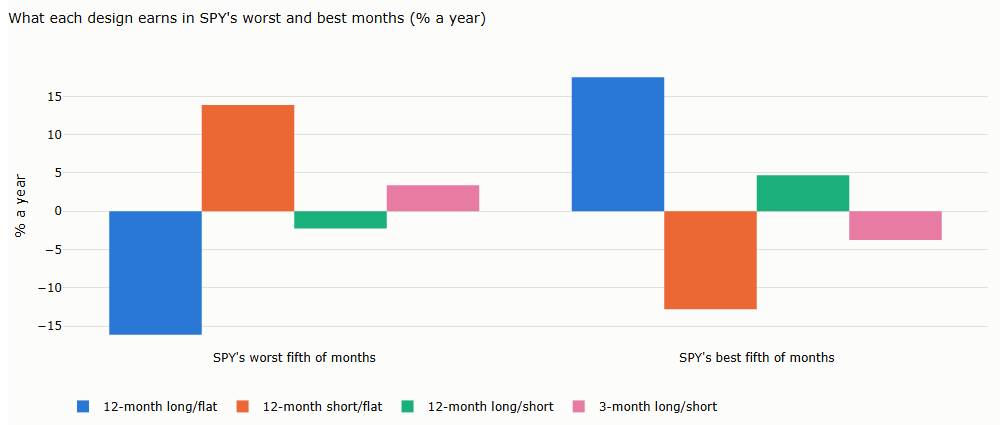

In [8]:
fig = go.Figure()
for j, (name, row) in enumerate(design.iterrows()):
    pass
x = ["SPY worst 20% of months", "SPY best 20% of months"]
for j, name in enumerate(["12-month long/flat", "12-month short/flat", "12-month long/short", "3-month long/short"]):
    fig.add_bar(name=name, x=["SPY's worst fifth of months", "SPY's best fifth of months"], y=design.loc[name, x].values, marker_color=SERIES[j])
fig.update_layout(barmode="group", title="What each design earns in SPY's worst and best months (% a year)", yaxis_title="% a year",
                  height=450, width=1000, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "06_01_direction_speed", FIG)
fig

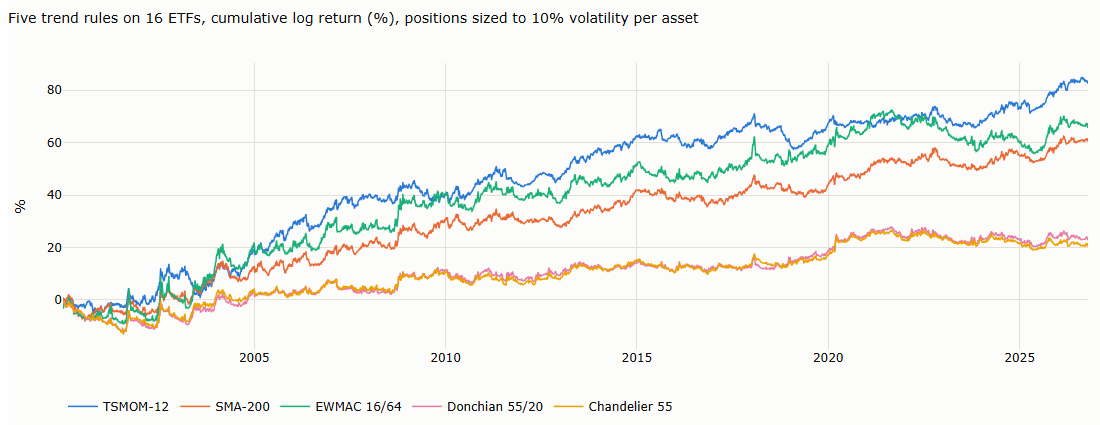

In [9]:
cum = daily.cumsum()
fig = go.Figure()
for j, k in enumerate(cum.columns):
    fig.add_scatter(x=cum.index, y=100 * cum[k], name=k, mode="lines", line=dict(width=1.5, color=SERIES[j % len(SERIES)]))
fig.update_layout(title="Five trend rules on 16 ETFs, cumulative log return (%), positions sized to 10% volatility per asset",
                  yaxis_title="%", height=450, width=1100, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "06_02_five_rules", FIG)
fig

## 2.3 Rules across their parameters (Table 2.2, charts E.2 and E.3)

Five families, each across its parameters, on the 16 ETFs: Sharpe ratio against the number of direction changes per
asset per year, before costs and after 5 basis points per unit traded.

                             family  parameter  trades per year  Sharpe gross  Sharpe at 5 bp
0                             TSMOM         10            35.79         -0.07           -0.53
1                             TSMOM         21            24.24          0.20           -0.11
2                             TSMOM         42            16.47          0.41            0.18
3                             TSMOM         63            13.06          0.29            0.10
4                             TSMOM        126             9.13          0.52            0.39
5                             TSMOM        252             5.95          0.56            0.47
6                             TSMOM        378             4.77          0.40            0.33
7                      Price vs SMA         10            45.23         -0.13           -0.70
8                      Price vs SMA         20            30.58          0.13           -0.27
9                      Price vs SMA         50            17

saved


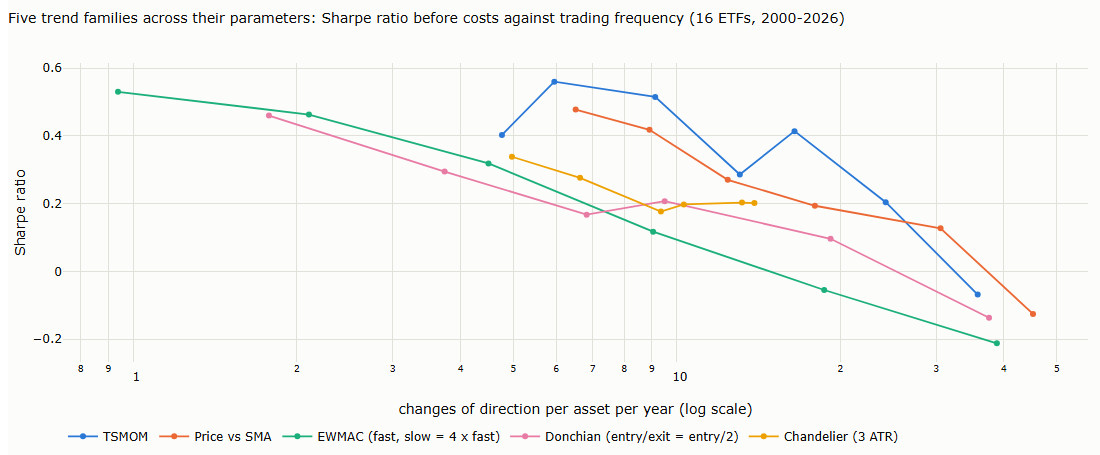

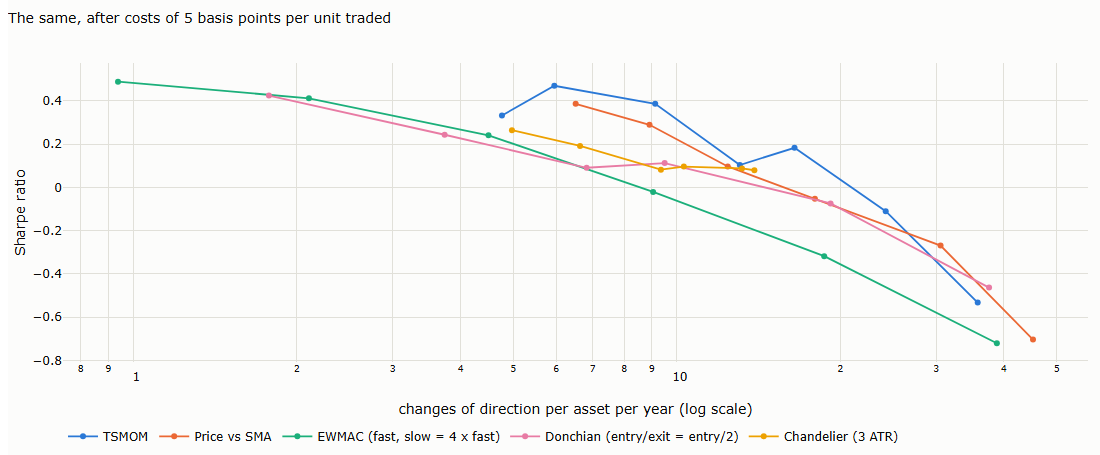

In [10]:
TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ", "AGG", "TLT", "GLD", "SLV", "GDX", "USO"]
D = load_ohlc(TICKERS, start="1993-01-01", cache=ROOT / "data" / "raw" / "nb05_ohlc.csv")
C, H, L = (D[f][TICKERS] for f in ("close", "high", "low"))
r = np.log(C).diff()
vol = r.ewm(span=60, min_periods=60).std()
TARGET = 0.10 / np.sqrt(252)
START = "2000-01-01"


def state_machine(c, enter_hi, enter_lo, exit_fn):
    out = pd.DataFrame(0.0, index=c.index, columns=c.columns)
    for t in c.columns:
        out[t] = exit_fn(t)
    return out


def donchian(entry):
    ex = max(entry // 2, 2)
    he, le = C.rolling(entry).max().shift(1), C.rolling(entry).min().shift(1)
    hx, lx = C.rolling(ex).max().shift(1), C.rolling(ex).min().shift(1)
    out = pd.DataFrame(0.0, index=C.index, columns=C.columns)
    for t in C.columns:
        pos, ps = 0.0, []
        for px, a, b, cx, dx in zip(C[t].to_numpy(), he[t].to_numpy(), le[t].to_numpy(), hx[t].to_numpy(), lx[t].to_numpy()):
            if np.isnan(px) or np.isnan(a):
                pos = 0.0
            elif pos == 0 and px > a:
                pos = 1.0
            elif pos == 0 and px < b:
                pos = -1.0
            elif pos == 1 and px < dx:
                pos = -1.0 if px < b else 0.0
            elif pos == -1 and px > cx:
                pos = 1.0 if px > a else 0.0
            ps.append(pos)
        out[t] = ps
    return out


tr = pd.concat({t: pd.concat([H[t] - L[t], (H[t] - C[t].shift()).abs(), (L[t] - C[t].shift()).abs()], axis=1).max(axis=1) for t in TICKERS}, axis=1)
atr = tr.rolling(20).mean()


def chandelier(entry, k=3.0):
    he, le = C.rolling(entry).max().shift(1), C.rolling(entry).min().shift(1)
    out = pd.DataFrame(0.0, index=C.index, columns=C.columns)
    for t in C.columns:
        pos, ext, ps = 0.0, np.nan, []
        for px, a, b, at in zip(C[t].to_numpy(), he[t].to_numpy(), le[t].to_numpy(), atr[t].to_numpy()):
            if np.isnan(px) or np.isnan(a) or np.isnan(at):
                pos = 0.0
            elif pos == 0:
                if px > a:
                    pos, ext = 1.0, px
                elif px < b:
                    pos, ext = -1.0, px
            elif pos == 1:
                ext = max(ext, px)
                if px < ext - k * at:
                    pos = 0.0
            else:
                ext = min(ext, px)
                if px > ext + k * at:
                    pos = 0.0
            ps.append(pos)
        out[t] = ps
    return out


def ewmac(fast):
    slow = 4 * fast
    raw = C.ewm(span=fast).mean() - C.ewm(span=slow).mean()
    f = raw / (C * vol)
    f = f / f.abs().loc[START:].median().median()
    return f.clip(-2, 2)


families = {
    "TSMOM": {n: np.sign(np.log(C).diff(n)) for n in (10, 21, 42, 63, 126, 252, 378)},
    "Price vs SMA": {n: np.sign(C - C.rolling(n).mean()) for n in (10, 20, 50, 100, 200, 300)},
    "EWMAC (fast, slow = 4 x fast)": {n: ewmac(n) for n in (2, 4, 8, 16, 32, 64)},
    "Donchian (entry/exit = entry/2)": {n: donchian(n) for n in (10, 20, 40, 55, 100, 200)},
    "Chandelier (3 ATR)": {n: chandelier(n) for n in (10, 20, 40, 55, 100, 200)},
}
rows = []
for fam, d in families.items():
    for n, sig in d.items():
        pos = sig * TARGET / vol
        port = (pos.shift(1) * r).loc[START:].mean(axis=1)
        to = pos.diff().abs().loc[START:].mean(axis=1)
        s = np.sign(sig).loc[START:]
        changes = (s.diff().abs() > 0).sum() / s.notna().sum() * 252      # direction changes per asset per year
        trades = changes.median()
        net = port - to * 5 / 1e4
        rows.append({"family": fam, "parameter": n, "trades per year": trades,
                     "Sharpe gross": np.sqrt(252) * port.mean() / port.std(), "Sharpe at 5 bp": np.sqrt(252) * net.mean() / net.std()})
df = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print(df.round(2).to_string())

for col, nm in (("Sharpe gross", "06_03_sharpe_vs_trades"), ("Sharpe at 5 bp", "06_04_sharpe_vs_trades_net")):
    fig = go.Figure()
    for j, (fam, g) in enumerate(df.groupby("family", sort=False)):
        g = g.sort_values("trades per year")
        fig.add_scatter(x=g["trades per year"], y=g[col], name=fam, mode="lines+markers", line=dict(width=1.8, color=SERIES[j]),
                        text=[str(p) for p in g["parameter"]], hovertemplate="%{text}: %{x:.1f} trades, Sharpe %{y:.2f}")
    fig.update_layout(title=("Five trend families across their parameters: Sharpe ratio before costs against trading frequency (16 ETFs, 2000-2026)" if col == "Sharpe gross" else "The same, after costs of 5 basis points per unit traded"),
                      xaxis=dict(title="changes of direction per asset per year (log scale)", type="log"), yaxis_title="Sharpe ratio",
                      height=480, width=1100, margin=dict(t=80), legend=dict(orientation="h", y=-0.2, x=0))
    save_figure(fig, nm, FIG)
print("saved")

## 2.4 Time series or cross-sectional: the example of 30 June 2022 (card 11)

The 16 ETFs ranked by their 12-month return divided by its volatility; long the top five, short the bottom five,
rebalanced monthly; against the time-series rule on the same day.

2022-06-30
     12-month return %  score  rank  cross-sectional  time-series
USO              61.09   1.18   1.0                1          1.0
XLE              38.94   1.01   2.0                1          1.0
XLU              14.29   0.80   3.0                1          1.0
GLD               1.71   0.12   4.0                1          1.0
VNQ              -8.01  -0.42   5.0                1         -1.0
XLK             -13.21  -0.52   6.0                0         -1.0
SPY             -10.62  -0.56   7.0                0         -1.0
XLF             -12.70  -0.61   8.0                0         -1.0
GDX             -18.01  -0.62   9.0                0         -1.0
QQQ             -20.48  -0.85  10.0                0         -1.0
EFA             -17.45  -1.06  11.0                0         -1.0
SLV             -23.04  -1.12  12.0               -1         -1.0
IWM             -25.37  -1.16  13.0               -1         -1.0
TLT             -19.11  -1.22  14.0               -1         -1.0

WindowsPath('C:/Users/maxgn/New Trading Models/figures/06_trend_following_map_and_machinery/06_c11_cross_sectional.html')

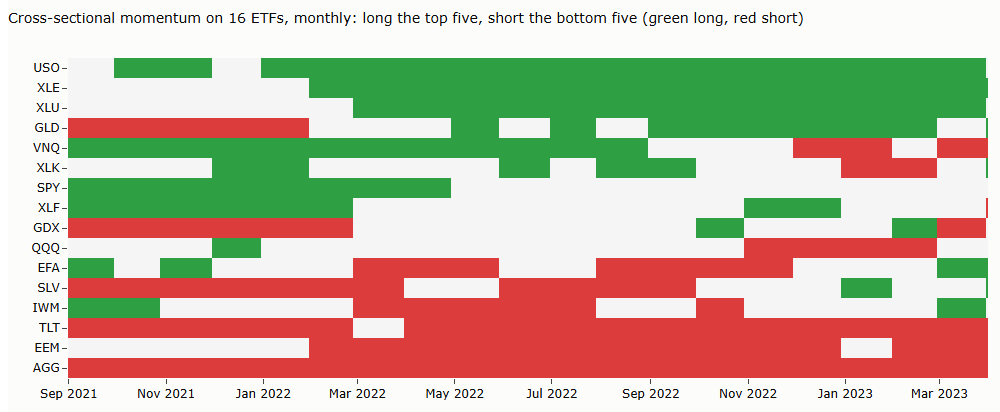

In [11]:
'''Lecture 6, card 11: cross-sectional momentum on the 16 ETFs; worked example on 30 June 2022.'''

TICK = ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ", "AGG", "TLT", "GLD", "SLV", "GDX", "USO"]
D = load_ohlc(TICK, start="2015-01-01", cache=ROOT / "data" / "raw" / "nb05_ohlc.csv")
c = D["close"][TICK].dropna(how="all")
r = np.log(c).diff()
L = 252
score = (np.log(c) - np.log(c.shift(L))) / (r.rolling(L).std() * np.sqrt(L))      # 12-month return in units of its own volatility
month_end = score.resample("ME").last().index
rank = score.rank(axis=1, ascending=False)
n = len(TICK); k = n // 3
pos_m = pd.DataFrame(0, index=score.index, columns=TICK)
pos_m[rank <= k] = 1; pos_m[rank > n - k] = -1
rebal = sorted({score.index[score.index <= m][-1] for m in month_end})
pos = pos_m.loc[rebal].reindex(score.index).ffill()   # rebalance monthly
t = pd.Timestamp("2022-06-30")
t = score.index[score.index <= t][-1]
ex = pd.DataFrame({"12-month return %": 100 * (c.loc[t] / c.shift(L).loc[t] - 1), "score": score.loc[t], "rank": rank.loc[t],
                   "cross-sectional": pos_m.loc[t], "time-series": np.sign(score.loc[t])}).sort_values("rank")
print(t.date()); print(ex.round(2).to_string())
print("time-series: long", int((ex["time-series"] > 0).sum()), "short", int((ex["time-series"] < 0).sum()),
      "| cross-sectional: long", int((ex["cross-sectional"] > 0).sum()), "short", int((ex["cross-sectional"] < 0).sum()))
w = slice("2021-09-01", "2023-03-31")
P = pos.loc[w]
order = list(ex.index)                                       # sorted by the June 2022 ranking
P = P[order]
changes = int((P.diff().abs() > 0).sum().sum())
print("position changes in the window:", changes)
fig = go.Figure(go.Heatmap(z=P.T.values, x=P.index, y=order, colorscale=[[0, "rgb(220,60,60)"], [0.5, "rgb(245,245,245)"], [1, "rgb(46,160,67)"]],
                           zmin=-1, zmax=1, showscale=False))
fig.update_layout(title="Cross-sectional momentum on 16 ETFs, monthly: long the top five, short the bottom five (green long, red short)",
                  height=430, width=1000, margin=dict(t=70, l=60), yaxis=dict(autorange="reversed"))
save_figure(fig, "06_c11_cross_sectional", FIG)

## Appendix: the model cards

Ten time-series rules on QQQ, September 2021 to March 2023, each with its signal, its position (green long, red short,
white flat) and the number of position changes in the window. Card 11 is the cross-sectional example above.

momentum flips in window: 12
sma flips in window: 2
ema flips in window: 10
ewmac flips in window: 10
donchian flips in window: 20
bollinger flips in window: 22
keltner flips in window: 28
supertrend flips in window: 12
reg t flips in window: 8
kalman flips in window: 4
done


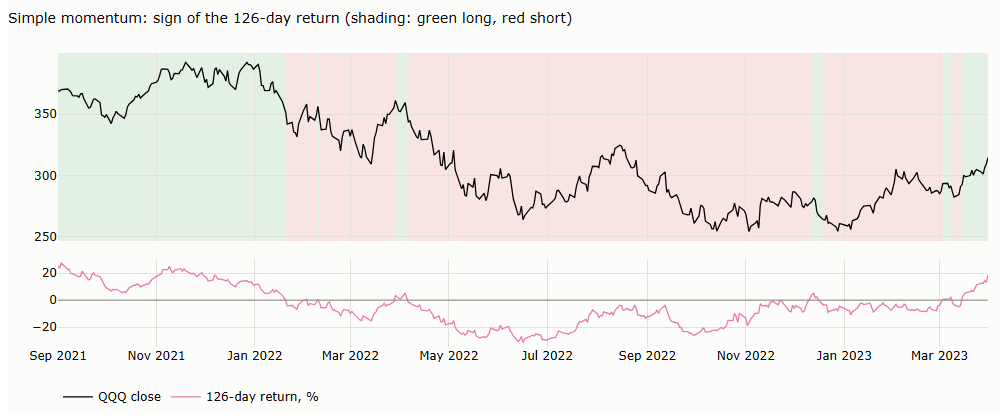

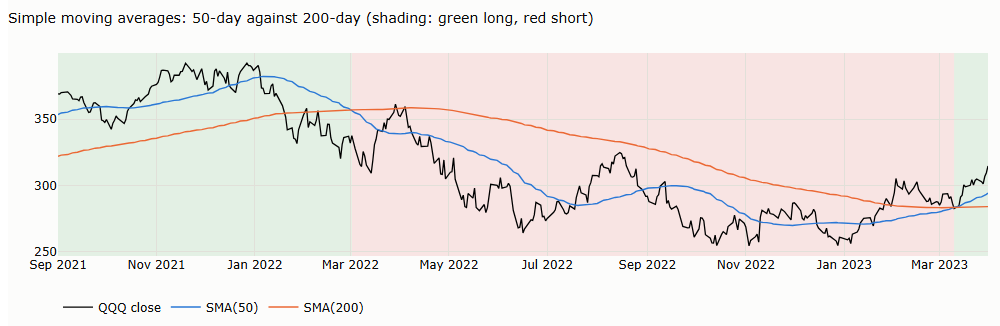

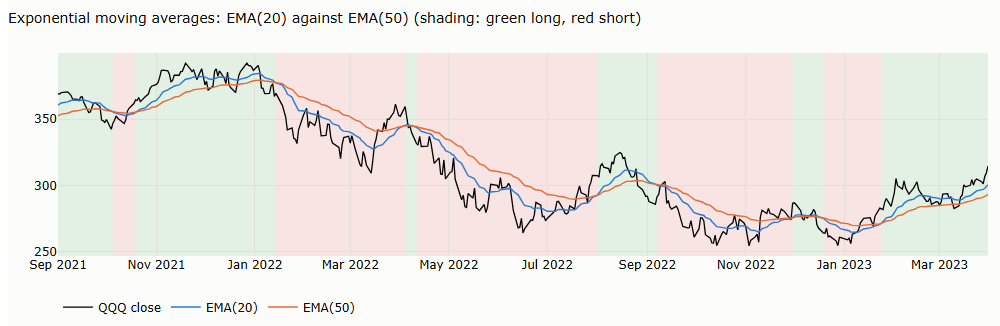

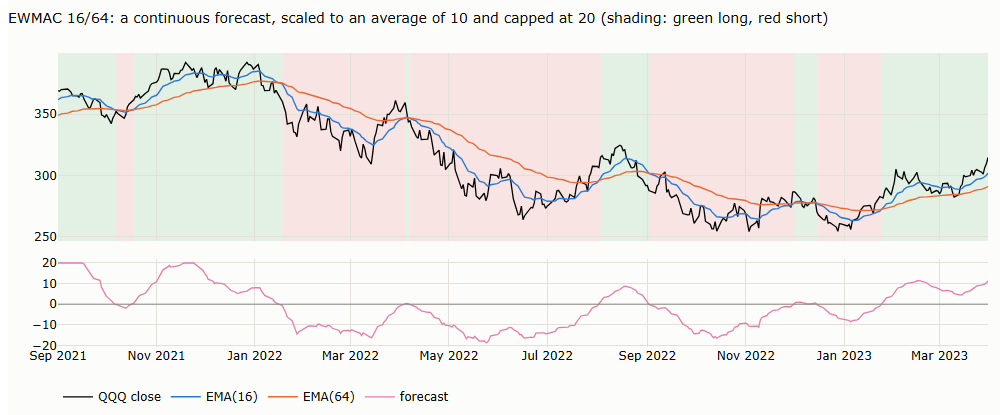

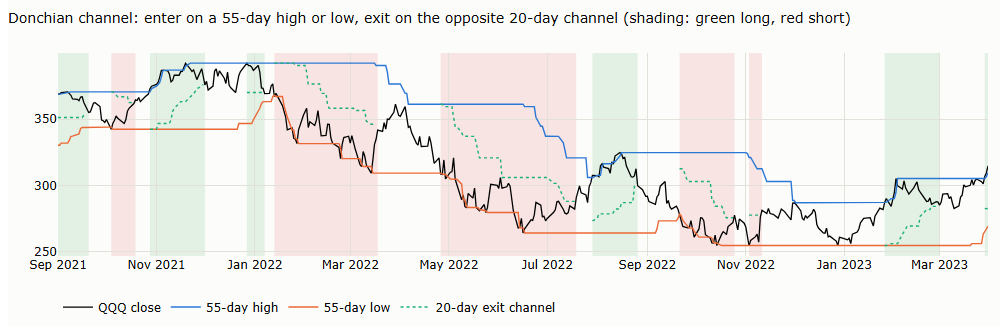

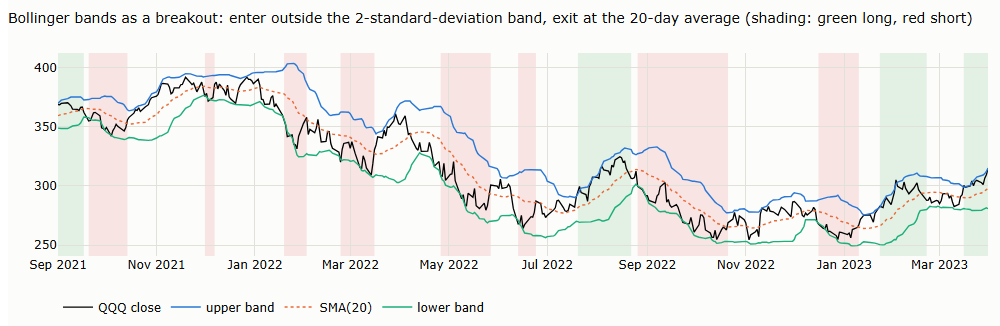

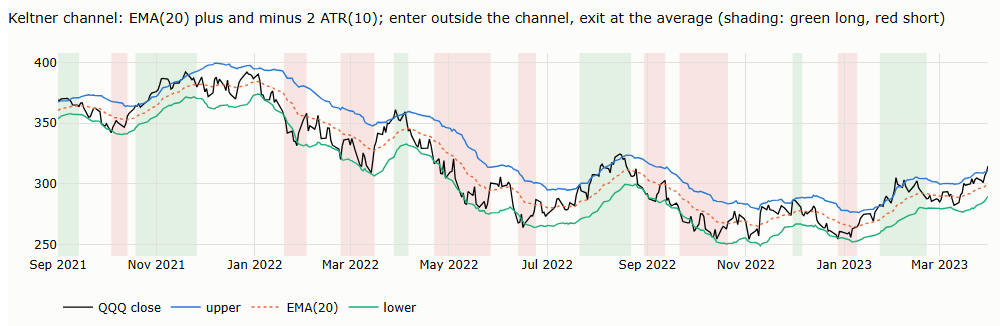

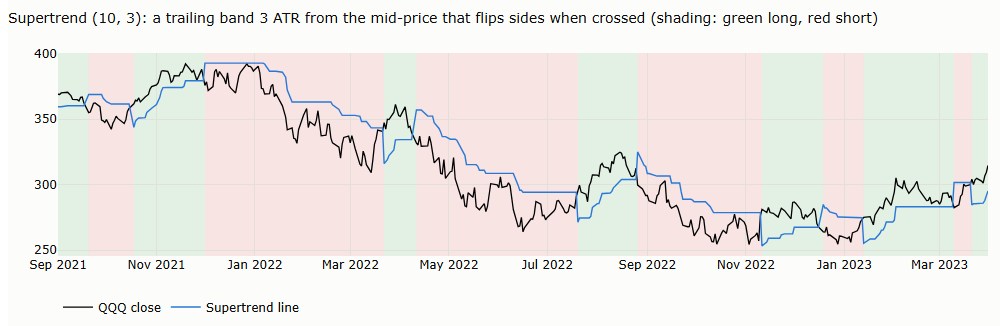

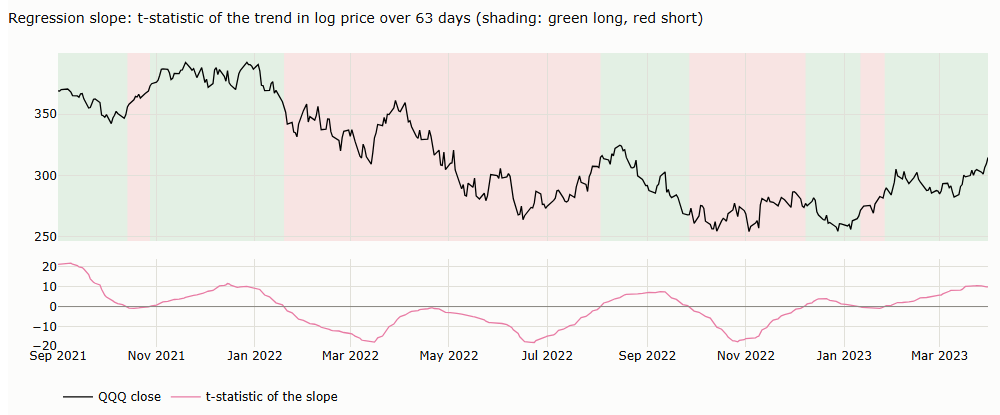

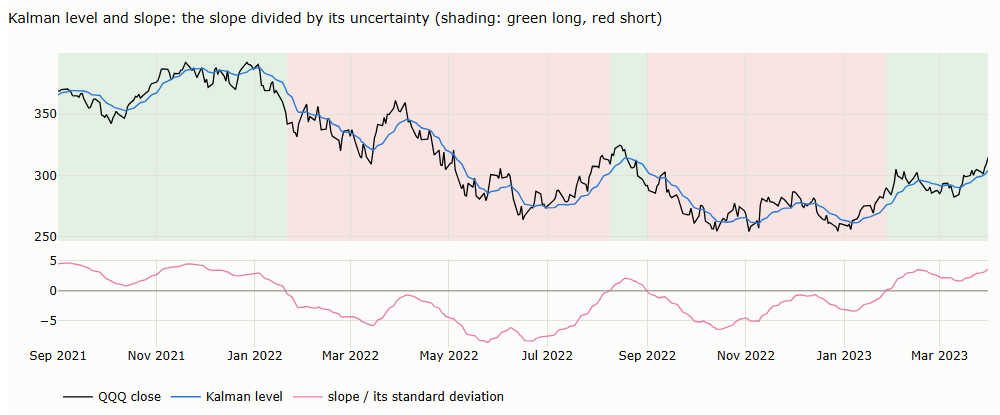

In [12]:
from plotly.subplots import make_subplots

D = load_ohlc(["QQQ"], start="2015-01-01", cache=ROOT / "data" / "raw" / "nb05_ohlc.csv")
c, h, l = D["close"]["QQQ"].dropna(), D["high"]["QQQ"].dropna(), D["low"]["QQQ"].dropna()
A, B = "2021-09-01", "2023-03-31"
w = slice(A, B)
GREEN, RED = "rgba(46,160,67,0.12)", "rgba(220,60,60,0.12)"


def shade(fig, pos, row=1):
    p = pos.loc[w].fillna(0)
    seg_start, cur = p.index[0], p.iloc[0]
    for t, v in list(p.items())[1:] + [(p.index[-1], None)]:
        if v != cur:
            if cur != 0:
                fig.add_vrect(x0=seg_start, x1=t, fillcolor=GREEN if cur > 0 else RED, line_width=0, layer="below", row=row, col=1)
            seg_start, cur = t, v


def card(name, title, lines, pos, lower=None, lower_name=None, lower_zero=True):
    rows = 2 if lower is not None else 1
    fig = make_subplots(rows=rows, cols=1, shared_xaxes=True, vertical_spacing=0.06, row_heights=[0.68, 0.32] if rows == 2 else [1])
    fig.add_scatter(x=c.loc[w].index, y=c.loc[w], name="QQQ close", mode="lines", line=dict(width=1.3, color="black"), row=1, col=1)
    for j, (nm, s, dash) in enumerate(lines):
        fig.add_scatter(x=s.loc[w].index, y=s.loc[w], name=nm, mode="lines", line=dict(width=1.4, color=SERIES[j], dash=dash), row=1, col=1)
    if lower is not None:
        fig.add_scatter(x=lower.loc[w].index, y=lower.loc[w], name=lower_name, mode="lines", line=dict(width=1.3, color=SERIES[3]), row=2, col=1)
        if lower_zero:
            fig.add_hline(y=0, line=dict(width=1, color=MUTED), row=2, col=1)
    shade(fig, pos)
    fig.update_layout(title=title + " (shading: green long, red short)", height=430 if rows == 2 else 340, width=1000,
                      margin=dict(t=60, b=40, l=50, r=20), legend=dict(orientation="h", y=-0.12 if rows == 2 else -0.18, x=0))
    save_figure(fig, name, FIG)


# 1 simple momentum
N = 126
mom = c / c.shift(N) - 1
card("06_c01_momentum", "Simple momentum: sign of the 126-day return", [], np.sign(mom), 100 * mom, "126-day return, %")
# 2 SMA crossover
s50, s200 = c.rolling(50).mean(), c.rolling(200).mean()
card("06_c02_sma", "Simple moving averages: 50-day against 200-day", [("SMA(50)", s50, "solid"), ("SMA(200)", s200, "solid")], np.sign(s50 - s200))
# 3 EMA crossover
e20, e50 = c.ewm(span=20).mean(), c.ewm(span=50).mean()
card("06_c03_ema", "Exponential moving averages: EMA(20) against EMA(50)", [("EMA(20)", e20, "solid"), ("EMA(50)", e50, "solid")], np.sign(e20 - e50))
# 4 EWMAC continuous forecast
r = np.log(c).diff(); vol = r.ewm(span=60, min_periods=60).std()
f = (c.ewm(span=16).mean() - c.ewm(span=64).mean()) / (c * vol)
f = (10 * f / f.loc["2005":].abs().median()).clip(-20, 20)
card("06_c04_ewmac", "EWMAC 16/64: a continuous forecast, scaled to an average of 10 and capped at 20", [("EMA(16)", c.ewm(span=16).mean(), "solid"), ("EMA(64)", c.ewm(span=64).mean(), "solid")], np.sign(f), f, "forecast")
# 5 Donchian 55/20
hi55, lo55 = c.rolling(55).max().shift(1), c.rolling(55).min().shift(1)
hi20, lo20 = c.rolling(20).max().shift(1), c.rolling(20).min().shift(1)
pos, ps = 0.0, []
for px, a, b, x, y in zip(c, hi55, lo55, hi20, lo20):
    if np.isnan(a): pos = 0.0
    elif pos == 0 and px > a: pos = 1.0
    elif pos == 0 and px < b: pos = -1.0
    elif pos == 1 and px < y: pos = -1.0 if px < b else 0.0
    elif pos == -1 and px > x: pos = 1.0 if px > a else 0.0
    ps.append(pos)
pos_don = pd.Series(ps, c.index)
card("06_c05_donchian", "Donchian channel: enter on a 55-day high or low, exit on the opposite 20-day channel",
     [("55-day high", hi55, "solid"), ("55-day low", lo55, "solid"), ("20-day exit channel", pd.Series(np.where(np.array(ps) > 0, lo20, np.where(np.array(ps) < 0, hi20, np.nan)), c.index), "dot")], pd.Series(ps, c.index))
# 6 Bollinger breakout
m20, sd20 = c.rolling(20).mean(), c.rolling(20).std()
up, dn = m20 + 2 * sd20, m20 - 2 * sd20
pos, ps = 0.0, []
for px, u, d_, m in zip(c, up, dn, m20):
    if np.isnan(u): pos = 0.0
    elif px > u: pos = 1.0
    elif px < d_: pos = -1.0
    elif (pos == 1 and px < m) or (pos == -1 and px > m): pos = 0.0
    ps.append(pos)
pos_bol = pd.Series(ps, c.index)
card("06_c06_bollinger", "Bollinger bands as a breakout: enter outside the 2-standard-deviation band, exit at the 20-day average",
     [("upper band", up, "solid"), ("SMA(20)", m20, "dot"), ("lower band", dn, "solid")], pd.Series(ps, c.index))
# 7 Keltner
tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
atr10, atr20 = tr.rolling(10).mean(), tr.rolling(20).mean()
mid = c.ewm(span=20).mean()
ku, kd = mid + 2 * atr10, mid - 2 * atr10
pos, ps = 0.0, []
for px, u, d_, m in zip(c, ku, kd, mid):
    if np.isnan(u): pos = 0.0
    elif px > u: pos = 1.0
    elif px < d_: pos = -1.0
    elif (pos == 1 and px < m) or (pos == -1 and px > m): pos = 0.0
    ps.append(pos)
pos_kel = pd.Series(ps, c.index)
card("06_c07_keltner", "Keltner channel: EMA(20) plus and minus 2 ATR(10); enter outside the channel, exit at the average",
     [("upper", ku, "solid"), ("EMA(20)", mid, "dot"), ("lower", kd, "solid")], pd.Series(ps, c.index))
# 8 Supertrend
n_, mult = 10, 3.0
atr = tr.ewm(alpha=1 / n_, adjust=False).mean()
hl2 = (h + l) / 2
bu, bl = hl2 + mult * atr, hl2 - mult * atr
fu, fl = bu.copy(), bl.copy()
trend = pd.Series(1.0, c.index)
for i in range(1, len(c)):
    fu.iloc[i] = bu.iloc[i] if (bu.iloc[i] < fu.iloc[i - 1] or c.iloc[i - 1] > fu.iloc[i - 1]) else fu.iloc[i - 1]
    fl.iloc[i] = bl.iloc[i] if (bl.iloc[i] > fl.iloc[i - 1] or c.iloc[i - 1] < fl.iloc[i - 1]) else fl.iloc[i - 1]
    if trend.iloc[i - 1] > 0:
        trend.iloc[i] = -1.0 if c.iloc[i] < fl.iloc[i] else 1.0
    else:
        trend.iloc[i] = 1.0 if c.iloc[i] > fu.iloc[i] else -1.0
st = pd.Series(np.where(trend > 0, fl, fu), c.index)
card("06_c08_supertrend", "Supertrend (10, 3): a trailing band 3 ATR from the mid-price that flips sides when crossed",
     [("Supertrend line", st, "solid")], trend)
# 9 regression slope t-statistic
Nr = 63
lp = np.log(c)
x = np.arange(Nr) - (Nr - 1) / 2
def tstat(y):
    b = (x * (y - y.mean())).sum() / (x ** 2).sum()
    resid = y - y.mean() - b * x
    se = np.sqrt((resid ** 2).sum() / (Nr - 2) / (x ** 2).sum())
    return b / se
tt = lp.rolling(Nr).apply(tstat, raw=True)
card("06_c09_regression", "Regression slope: t-statistic of the trend in log price over 63 days", [], np.sign(tt), tt, "t-statistic of the slope")
# 10 Kalman slope (level + slope, Lecture 4 style)
y = np.log(c.to_numpy())
q_l, q_s, rr = 1.3e-2, 6e-6, 1.0
F = np.array([[1, 1], [0, 1]]); Hm = np.array([1.0, 0.0])
xs, P = np.array([y[0], 0.0]), np.eye(2) * 1e3
R = 0.018 ** 2; Q = np.diag([q_l, q_s]) * R
lev, slp, sd = [], [], []
for v in y:
    xs = F @ xs; P = F @ P @ F.T + Q
    S = Hm @ P @ Hm + R; K = P @ Hm / S
    xs = xs + K * (v - Hm @ xs); P = P - np.outer(K, Hm @ P)
    lev.append(xs[0]); slp.append(xs[1]); sd.append(np.sqrt(P[1, 1]))
slp, sd = pd.Series(slp, c.index), pd.Series(sd, c.index)
zt = slp / sd
card("06_c10_kalman", "Kalman level and slope: the slope divided by its uncertainty", [("Kalman level", pd.Series(np.exp(lev), c.index), "solid")], np.sign(zt), zt, "slope / its standard deviation")
# summary of flips in the window
don = pd.Series(ps, c.index)
for nm, p_ in [("momentum", np.sign(mom)), ("sma", np.sign(s50 - s200)), ("ema", np.sign(e20 - e50)), ("ewmac", np.sign(f)), ("donchian", pos_don), ("bollinger", pos_bol), ("keltner", pos_kel), ("supertrend", trend), ("reg t", np.sign(tt)), ("kalman", np.sign(zt))]:
    q = p_.loc[w]
    print(nm, "flips in window:", int((q.diff().abs() > 0).sum()))
print("done")